In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
variables = pd.read_csv(
    "../Data/Procesados/variables_estaciones_ECOBICI.csv"
)

actividad = pd.read_csv(
    "../Data/Procesados/actividad_mensual_ECOBICI.csv"
)

print("Variables:", variables.shape)
print("Actividad:", actividad.shape)

print("\nColumnas de actividad:")
print(actividad.columns.tolist())

actividad.head()

Variables: (677, 13)
Actividad: (16270, 5)

Columnas de actividad:
['mes', 'estacion', 'arribos', 'retiros', 'movimientos']


,mes,estacion,arribos,retiros,movimientos
0,2024-10,001,9070,8787,17857
1,2024-10,002,3734,3543,7277
2,2024-10,003,3746,4056,7802
3,2024-10,004,5040,4761,9801
4,2024-10,005,5354,5454,10808


In [7]:
# Preparar fechas
actividad["mes"] = pd.to_datetime(
    actividad["mes"], format="%Y-%m"
)

# Normalizar identificadores conservándolos como texto
def normalizar_id(serie):
    return (
        serie.astype("string")
        .str.strip()
        .str.replace(r"^0+(?=\d+$)", "", regex=True)
    )

actividad["num_cicloe"] = normalizar_id(actividad["estacion"])
variables["num_cicloe"] = normalizar_id(variables["num_cicloe"])

# Filtrar los últimos 12 meses
actividad_12m = actividad[
    actividad["mes"].between("2025-10-01", "2026-09-01")
].copy()

# Agregar movimientos por estación
demanda = (
    actividad_12m
    .groupby("num_cicloe", as_index=False)
    .agg(
        movimientos_anuales=("movimientos", "sum"),
        meses_con_datos=("mes", "nunique")
    )
)

demanda["movimientos_diarios"] = (
    demanda["movimientos_anuales"] / 365
)

demanda.head()

,num_cicloe,movimientos_anuales,meses_con_datos,movimientos_diarios
0,1,156896,12,429.852055
1,10,122393,12,335.323288
2,100,30418,12,83.336986
3,1000,596,10,1.632877
4,102,35865,12,98.260274


In [8]:
datos_modelo = variables.merge(
    demanda,
    on="num_cicloe",
    how="left",
    validate="one_to_one"
)

print("Dimensiones:", datos_modelo.shape)
print("Estaciones sin demanda:", datos_modelo["movimientos_diarios"].isna().sum())

print("\nMeses con datos:")
print(datos_modelo["meses_con_datos"].value_counts(dropna=False).sort_index())

Dimensiones: (677, 16)
Estaciones sin demanda: 0

Meses con datos:
meses_con_datos
9       2
10      1
11      4
12    670
Name: count, dtype: int64


In [9]:
datos_modelo.loc[
    datos_modelo["meses_con_datos"] < 12,
    [
        "num_cicloe",
        "alcaldia",
        "meses_con_datos",
        "movimientos_anuales",
        "movimientos_diarios"
    ]
].sort_values("meses_con_datos")

,num_cicloe,alcaldia,meses_con_datos,movimientos_anuales,movimientos_diarios
674,699,Coyoacan,9,13698,37.528767
614,402,Benito Juarez,9,34730,95.150685
297,84,Cuauhtemoc,10,75421,206.632877
38,483,Miguel Hidalgo,11,22486,61.605479
267,244,Miguel Hidalgo,11,24516,67.167123
44,491,Miguel Hidalgo,11,29718,81.419178
350,459,Miguel Hidalgo,11,38349,105.065753


In [10]:
datos_modelo = datos_modelo[
    datos_modelo["meses_con_datos"] == 12
].copy()

print("Estaciones para modelado:", len(datos_modelo))

datos_modelo.to_csv(
    "../Data/Procesados/datos_modelo_ECOBICI.csv",
    index=False
)

Estaciones para modelado: 670


count    670.000000
mean     151.768698
std       96.919972
min       16.810959
25%       83.404110
50%      128.534247
75%      193.282877
max      892.219178
Name: movimientos_diarios, dtype: float64


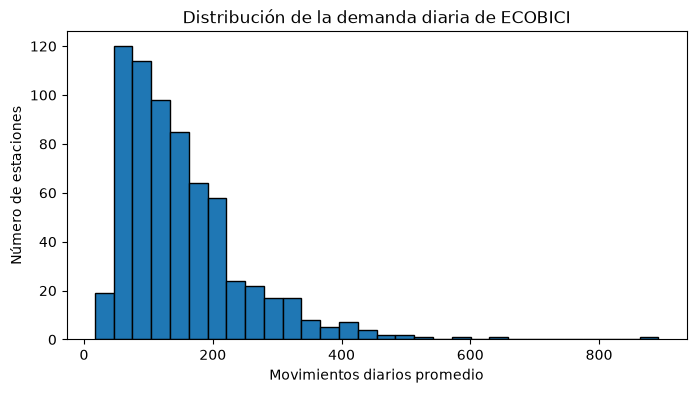

In [11]:
print(datos_modelo["movimientos_diarios"].describe())

plt.figure(figsize=(8, 4))

plt.hist(
    datos_modelo["movimientos_diarios"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Movimientos diarios promedio")
plt.ylabel("Número de estaciones")
plt.title("Distribución de la demanda diaria de ECOBICI")

plt.show()

In [12]:
predictoras = [
    "poblacion_500m",
    "negocios_500m",
    "personal_500m",
    "dist_metro",
    "dist_metrobus",
    "infra_ciclista_500m",
    "estaciones_ecobici_500m",
    "universidades_500m",
    "dist_centro"
]

correlaciones = (
    datos_modelo[predictoras + ["movimientos_diarios"]]
    .corr(method="spearman")["movimientos_diarios"]
    .drop("movimientos_diarios")
    .sort_values(ascending=False)
)

print(correlaciones.round(3))

infra_ciclista_500m        0.430
negocios_500m              0.398
personal_500m              0.384
universidades_500m         0.342
estaciones_ecobici_500m    0.340
poblacion_500m            -0.021
dist_metro                -0.239
dist_metrobus             -0.401
dist_centro               -0.463
Name: movimientos_diarios, dtype: float64


In [13]:
from itertools import combinations

corr = datos_modelo[predictoras].corr(method="spearman")

pares = pd.DataFrame([
    (a, b, corr.loc[a, b])
    for a, b in combinations(predictoras, 2)
], columns=["variable_1", "variable_2", "correlacion"])

pares["abs_corr"] = pares["correlacion"].abs()

pares.sort_values("abs_corr", ascending=False).head(10)

,variable_1,variable_2,correlacion,abs_corr
8,negocios_500m,personal_500m,0.710572,0.710572
18,personal_500m,estaciones_ecobici_500m,0.633639,0.633639
14,negocios_500m,dist_centro,-0.597407,0.597407
30,infra_ciclista_500m,estaciones_ecobici_500m,0.568418,0.568418
31,infra_ciclista_500m,universidades_500m,0.553908,0.553908
16,personal_500m,dist_metrobus,-0.540604,0.540604
26,dist_metrobus,infra_ciclista_500m,-0.538197,0.538197
19,personal_500m,universidades_500m,0.511475,0.511475
33,estaciones_ecobici_500m,universidades_500m,0.503335,0.503335
12,negocios_500m,estaciones_ecobici_500m,0.502936,0.502936


## Conclusiones del análisis exploratorio

El análisis exploratorio permitió identificar las principales relaciones entre las características urbanas del entorno de las estaciones ECOBICI y su demanda.

**1. Construcción del conjunto de datos**

Se integraron nueve variables explicativas para 677 estaciones ECOBICI. Para el modelado inicial se seleccionaron 670 estaciones con registros de actividad en los 12 meses comprendidos entre octubre de 2025 y septiembre de 2026.

La variable objetivo se definió como el promedio diario de movimientos (retiros más arribos) durante ese periodo.

**2. Distribución de la demanda**

La demanda presenta una distribución asimétrica hacia la derecha: la mayoría de las estaciones registra niveles de actividad relativamente bajos o moderados, mientras que un grupo reducido concentra valores elevados.

Esta característica deberá considerarse al evaluar los errores de los modelos predictivos.

**3. Relación entre las variables urbanas y la demanda**

Las asociaciones monotónicas más importantes, medidas mediante la correlación de Spearman, fueron:

- Distancia al centro: **−0.463**.
- Infraestructura ciclista cercana: **0.430**.
- Distancia al Metrobús: **−0.401**.
- Número de negocios cercanos: **0.398**.
- Personal ocupado cercano: **0.384**.

Estos resultados sugieren que la centralidad, la infraestructura ciclista, la conectividad con el transporte público y la actividad económica están asociadas con la utilización de ECOBICI.

Por otro lado, la población residente dentro de 500 metros presentó una correlación prácticamente nula (**−0.021**). Esto no implica que la población carezca de utilidad predictiva ni que deba excluirse del modelo.

**4. Relación entre las variables explicativas**

Se identificaron correlaciones relevantes entre algunas variables, especialmente entre el número de negocios y el personal ocupado (**0.711**).

Estas asociaciones sugieren que algunas variables capturan características similares del entorno urbano. Sin embargo, no se considera necesario eliminar variables en esta etapa.

**5. Implicaciones para el modelado**

El análisis exploratorio justifica evaluar modelos capaces de incorporar relaciones no lineales entre las características urbanas y la demanda.

Se conservarán inicialmente las nueve variables explicativas y se comparará su capacidad predictiva mediante modelos de distinta complejidad.

Dada la naturaleza geográfica de los datos, será importante utilizar un esquema de validación espacial para evitar sobreestimar el desempeño predictivo.

**Limitaciones:** las correlaciones observadas no representan relaciones causales; la infraestructura ciclista se mide por longitud y no por calidad; y la disponibilidad de registros mensuales no garantiza que las estaciones hayan operado todos los días del periodo.